# Partie 1 - AdaBoost sur MNIST

On distingue deux classes binaires : les chiffres de 0 a 4 (classe 0) et ceux de 5 a 9 (classe 1). On compare des decision stumps, des perceptrons et des arbres de decision de profondeurs differentes, puis on observe les matrices de confusion a plusieurs etapes du boosting.

Les images restent representees par leurs 784 pixels : aucune reduction de dimension par ACP n'est appliquee.

In [22]:
from pathlib import Path

import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
)
from sklearn.neural_network import MLPRegressor
from sklearn.tree import DecisionTreeClassifier

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## Chargement et preparation des donnees

MNIST fournit 60 000 exemples d'entrainement et 10 000 exemples de test. Chaque image contient 784 pixels en niveaux de gris. Les pixels seront normalises pour entrainer l'autoencodeur.

In [23]:
from sklearn.datasets import fetch_openml

directory = "data"
#telecharger jeu de donnée MNIST
mnist = fetch_openml('mnist_784', version=1, data_home=directory, as_frame=False, parser='liac-arff')


In [24]:
X_train = mnist.data[:60000]
y_train = mnist.target[:60000]

X_test = mnist.data[60000:70000]
y_test = mnist.target[60000:70000]

print('Train :',X_train.shape, y_train.shape)
print('Test :', X_test.shape, y_test.shape)

Train : (60000, 784) (60000,)
Test : (10000, 784) (10000,)


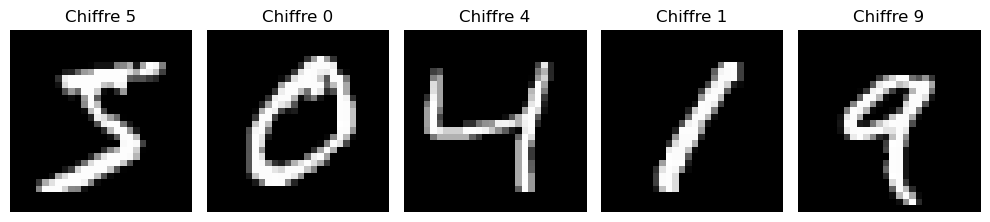

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(10, 2.5))
for ax, image, label in zip(axes, X_train[:5], y_train[:5]):
    ax.imshow(image.reshape(28, 28), cmap='gray')
    ax.set_title(f'Chiffre {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Construction des deux classes

Le label binaire 0 correspond aux chiffres 0, 1, 2, 3 et 4 ; le label 1 correspond aux chiffres 5, 6, 7, 8 et 9.

In [26]:
noms_classes = ['Chiffres 0-4', 'Chiffres 5-9']

X_train_bin, X_test_bin = X_train, X_test
y_train_bin = (y_train.astype(int) >= 5).astype(np.int8)
y_test_bin = (y_test.astype(int) >= 5).astype(np.int8)

print('Effectifs train :', dict(zip(*np.unique(y_train_bin, return_counts=True))))
print('Effectifs test  :', dict(zip(*np.unique(y_test_bin, return_counts=True))))
print('Dimensions utilisees :', X_train_bin.shape, X_test_bin.shape)

Effectifs train : {0: 30596, 1: 29404}
Effectifs test  : {0: 5139, 1: 4861}
Dimensions utilisees : (60000, 784) (10000, 784)


## Algorithme AdaBoost binaire

On utilise le mode SAMME, car le perceptron ne fournit pas de probabilites (`predict_proba`).

In [27]:
def creer_adaboost(classifieur, nb_etapes):
    return AdaBoostClassifier(
        estimator=classifieur,
        n_estimators=nb_etapes,
        algorithm='SAMME',
        random_state=RANDOM_SEED,
    )

## Experiences et matrices de confusion

On compare un stump (arbre de profondeur 1), un perceptron et trois profondeurs d'arbres. Les matrices sont calculees aux etapes demandees ; si un modele converge avant, le nombre effectif d'etapes est indique.

In [16]:
NB_ETAPES = 50
ETAPES_A_EVALUER = [1, 10, 20, 30, 40, 50]

configurations = {
    'Stump (profondeur 1)': DecisionTreeClassifier(
        max_depth=1, random_state=RANDOM_SEED
    ),
    'Perceptron': Perceptron(
        max_iter=5, tol=None, random_state=RANDOM_SEED
    ),
    'Arbre (profondeur 3)': DecisionTreeClassifier(
        max_depth=3, random_state=RANDOM_SEED
    ),
    'Arbre (profondeur 5)': DecisionTreeClassifier(
        max_depth=5, random_state=RANDOM_SEED
    ),
    'Arbre (profondeur 10)': DecisionTreeClassifier(
        max_depth=10, random_state=RANDOM_SEED
    ),
}

resultats = []
matrices = {}
modeles = {}

for nom, classifieur in configurations.items():
    print(f'Entrainement : {nom}')
    modele = creer_adaboost(classifieur, NB_ETAPES)
    modele.fit(X_train_bin, y_train_bin)
    if not modele.estimators_:
        raise RuntimeError(f'Aucun estimateur AdaBoost appris pour {nom}.')
    modeles[nom] = modele
    matrices[nom] = {}

    etapes_effectives = sorted(
        {min(n, len(modele.estimators_)) for n in ETAPES_A_EVALUER}
    )
    for n, y_pred in enumerate(modele.staged_predict(X_test_bin), start=1):
        if n not in etapes_effectives:
            continue
        cm = confusion_matrix(y_test_bin, y_pred, labels=[0, 1])
        matrices[nom][n] = cm
        resultats.append({
            'Classifieur faible': nom,
            'Etapes': n,
            'Accuracy': accuracy_score(y_test_bin, y_pred),
            'Balanced accuracy': balanced_accuracy_score(y_test_bin, y_pred),
            'Matrice de confusion': cm.tolist(),
        })
        print(f'{nom} - {n} etapes - matrice :\n{cm}')

table_resultats = pd.DataFrame(resultats)
table_resultats

Entrainement : Stump (profondeur 1)
Stump (profondeur 1) - 1 etapes - matrice :
[[2990 2149]
 [ 857 4004]]
Stump (profondeur 1) - 10 etapes - matrice :
[[3705 1434]
 [ 895 3966]]
Stump (profondeur 1) - 20 etapes - matrice :
[[4051 1088]
 [ 932 3929]]
Stump (profondeur 1) - 30 etapes - matrice :
[[4066 1073]
 [ 953 3908]]
Stump (profondeur 1) - 40 etapes - matrice :
[[4147  992]
 [ 953 3908]]
Stump (profondeur 1) - 50 etapes - matrice :
[[4127 1012]
 [ 917 3944]]
Entrainement : Perceptron
Perceptron - 1 etapes - matrice :
[[4632  507]
 [1447 3414]]
Perceptron - 9 etapes - matrice :
[[4501  638]
 [1040 3821]]
Entrainement : Arbre (profondeur 3)
Arbre (profondeur 3) - 1 etapes - matrice :
[[3583 1556]
 [ 879 3982]]
Arbre (profondeur 3) - 10 etapes - matrice :
[[4314  825]
 [ 824 4037]]
Arbre (profondeur 3) - 20 etapes - matrice :
[[4509  630]
 [ 596 4265]]
Arbre (profondeur 3) - 30 etapes - matrice :
[[4578  561]
 [ 521 4340]]
Arbre (profondeur 3) - 40 etapes - matrice :
[[4715  424]
 [ 4

,Classifieur faible,Etapes,Accuracy,Balanced accuracy,Matrice de confusion
0,Stump (profondeur 1),1,0.6994,0.702762,"[[2990, 2149], [857, 4004]]"
1,Stump (profondeur 1),10,0.7671,0.768419,"[[3705, 1434], [895, 3966]]"
2,Stump (profondeur 1),20,0.7980,0.798278,"[[4051, 1088], [932, 3929]]"
3,Stump (profondeur 1),30,0.7974,0.797577,"[[4066, 1073], [953, 3908]]"
4,Stump (profondeur 1),40,0.8055,0.805458,"[[4147, 992], [953, 3908]]"
5,Stump (profondeur 1),50,0.8071,0.807215,"[[4127, 1012], [917, 3944]]"
6,Perceptron,1,0.8046,0.801834,"[[4632, 507], [1447, 3414]]"
7,Perceptron,9,0.8322,0.830952,"[[4501, 638], [1040, 3821]]"
8,Arbre (profondeur 3),1,0.7565,0.758195,"[[3583, 1556], [879, 3982]]"
9,Arbre (profondeur 3),10,0.8351,0.834975,"[[4314, 825], [824, 4037]]"


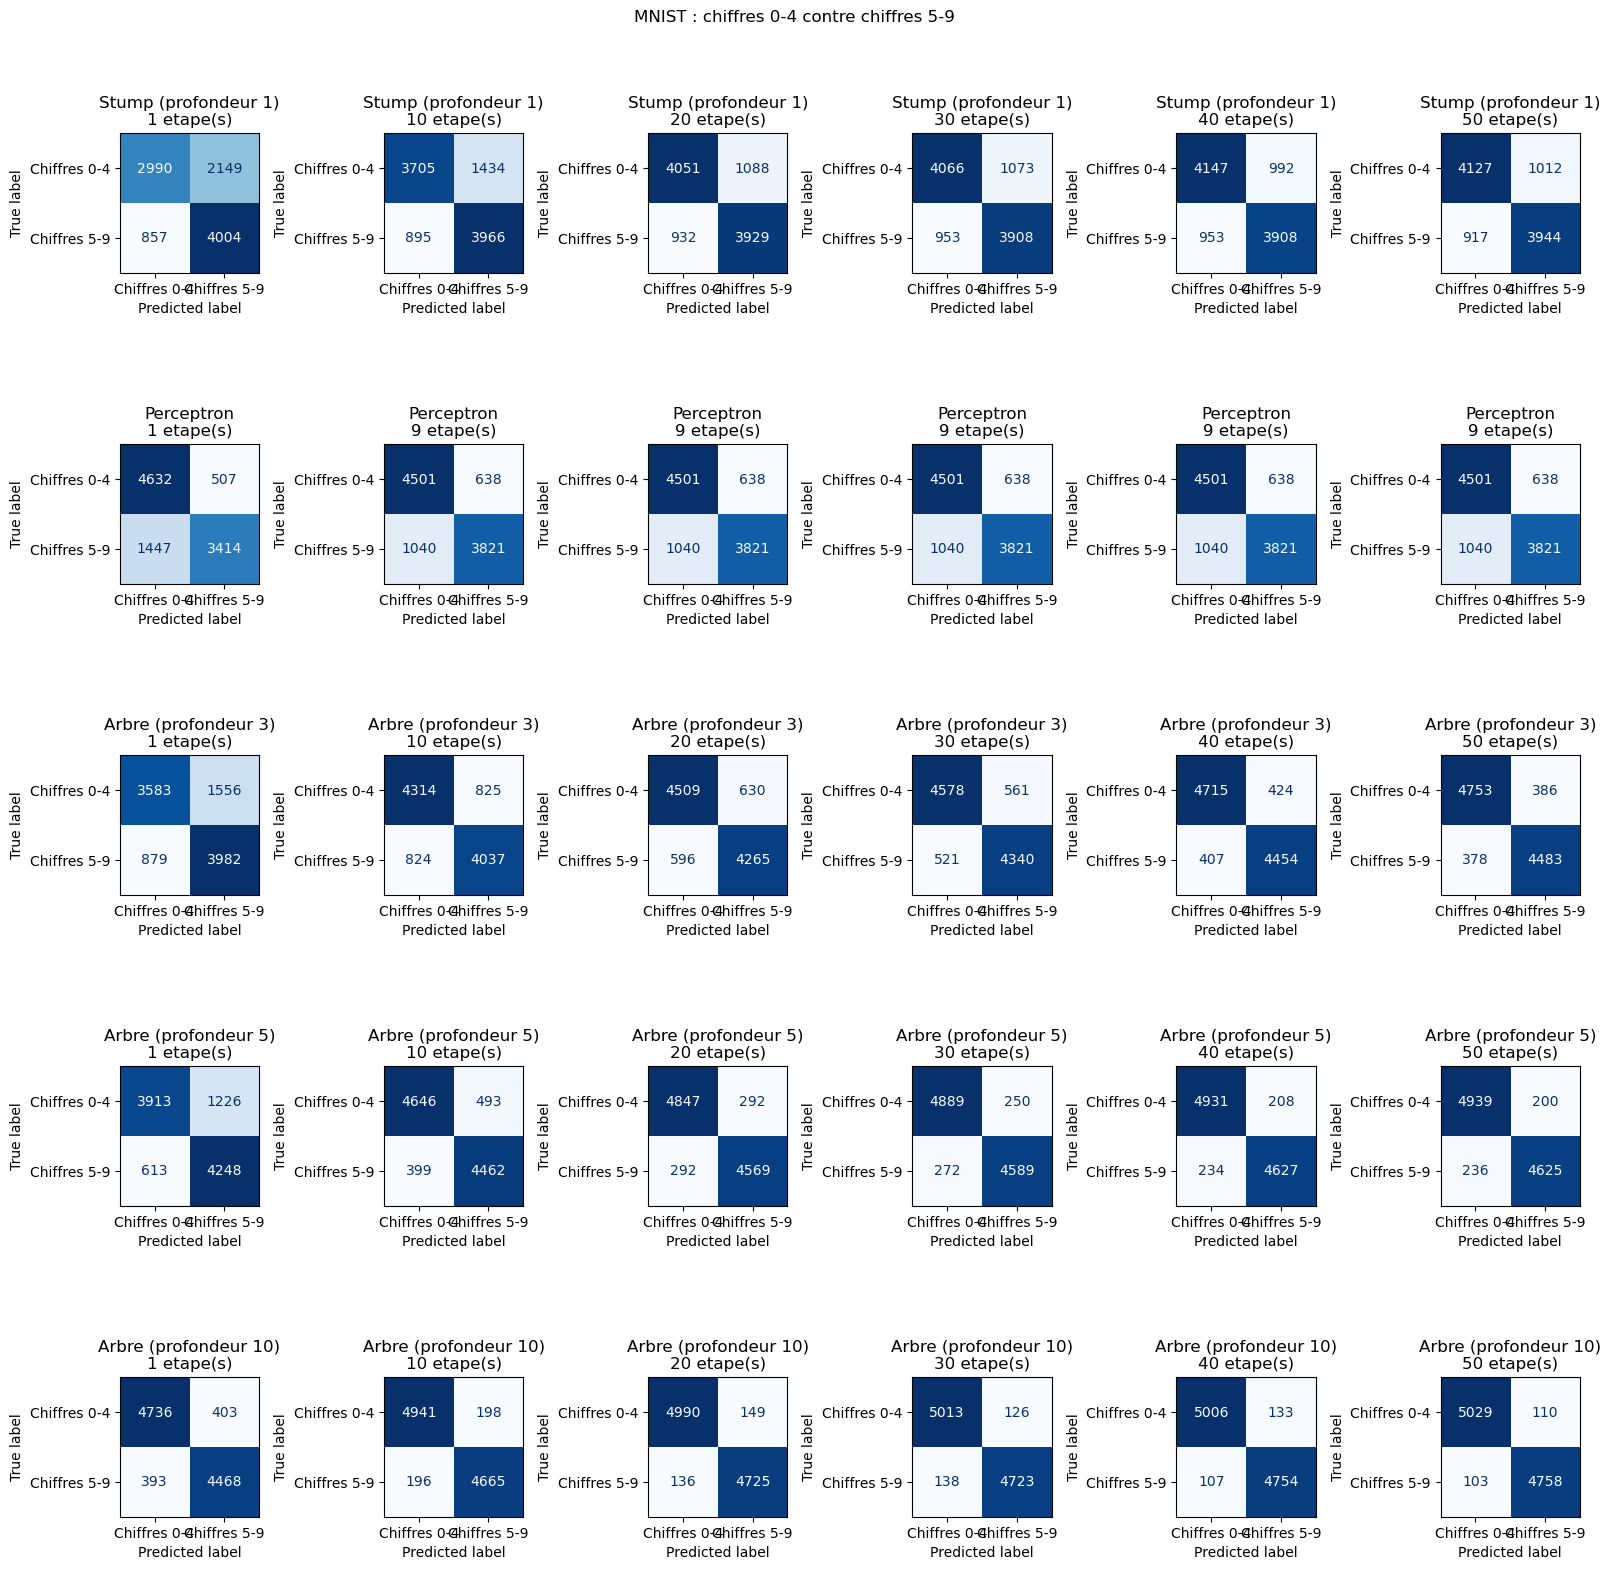

In [17]:
nb_lignes = len(configurations)
fig, axes = plt.subplots(
    nb_lignes, len(ETAPES_A_EVALUER),
    figsize=(16, 3.2 * nb_lignes),
    squeeze=False,
)

for i, (nom, matrices_modele) in enumerate(matrices.items()):
    for j, n_demande in enumerate(ETAPES_A_EVALUER):
        n = min(n_demande, max(matrices_modele))
        cm = matrices_modele[n]
        ConfusionMatrixDisplay(cm, display_labels=noms_classes).plot(
            ax=axes[i, j], cmap='Blues', colorbar=False, values_format='d'
        )
        axes[i, j].set_title(f'{nom}\n{n} etape(s)')

fig.suptitle('MNIST : chiffres 0-4 contre chiffres 5-9', y=1.002)
fig.tight_layout()
plt.show()

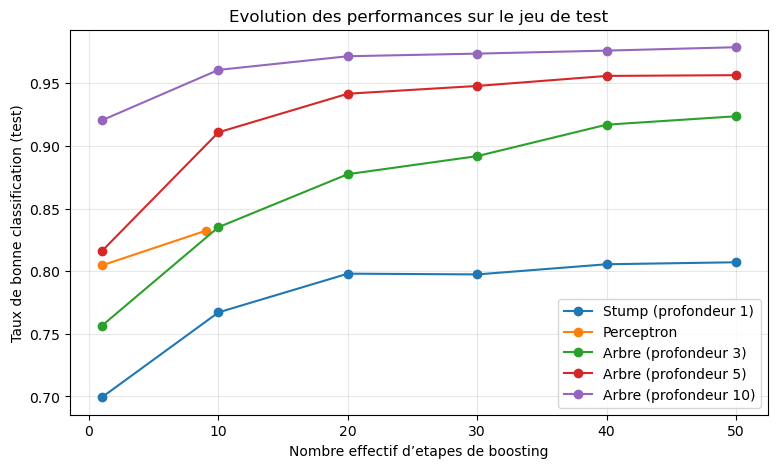

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
for nom, matrices_modele in matrices.items():
    scores = []
    etapes = []
    for n in sorted(matrices_modele):
        cm = matrices_modele[n]
        scores.append(np.trace(cm) / cm.sum())
        etapes.append(n)
    ax.plot(etapes, scores, marker='o', label=nom)

ax.set_xlabel('Nombre effectif d’etapes de boosting')
ax.set_ylabel('Taux de bonne classification (test)')
ax.set_title('Evolution des performances sur le jeu de test')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Bilan

Le tableau ci-dessous classe les configurations selon leur accuracy et leur balanced accuracy. La matrice de confusion permet de verifier si les erreurs concernent davantage l'un des deux groupes. Pour conclure, comparer les meilleurs resultats a faible et grand nombre d'etapes, ainsi que les erreurs des stumps, du perceptron et des arbres plus profonds. Les scores observes a l'execution du notebook servent de base aux conclusions (ils ne sont pas fixes a l'avance).

In [19]:
classement = table_resultats.sort_values(
    ['Balanced accuracy', 'Accuracy'], ascending=False
).reset_index(drop=True)
display(classement[['Classifieur faible', 'Etapes', 'Accuracy', 'Balanced accuracy']])

meilleur = classement.iloc[0]
print(
    f"Meilleure configuration : {meilleur['Classifieur faible']} a "
    f"{int(meilleur['Etapes'])} etape(s), balanced accuracy = "
    f"{meilleur['Balanced accuracy']:.3f}."
)

,Classifieur faible,Etapes,Accuracy,Balanced accuracy
0,Arbre (profondeur 10),50,0.9787,0.978703
1,Arbre (profondeur 10),40,0.9760,0.976054
2,Arbre (profondeur 10),30,0.9736,0.973546
3,Arbre (profondeur 10),20,0.9715,0.971514
4,Arbre (profondeur 10),10,0.9606,0.960575
5,Arbre (profondeur 5),50,0.9564,0.956266
6,Arbre (profondeur 5),40,0.9558,0.955693
7,Arbre (profondeur 5),30,0.9478,0.947698
8,Arbre (profondeur 5),20,0.9416,0.941555
9,Arbre (profondeur 3),50,0.9236,0.923563


Meilleure configuration : Arbre (profondeur 10) a 50 etape(s), balanced accuracy = 0.979.


## 2. Cartes de saillance dans l'espace des pixels

On reprend les cinq classifieurs de la partie 1, sans les reentrainer. Les cartes sont affichees toutes les 10 etapes (10, 20, 30, 40 et 50). Les matrices de confusion deja calculees sont reutilisees pour indiquer l'accuracy. Bleu = contribution vers la classe 0 (chiffres 0 a 4) ; rouge = contribution vers la classe 1 (chiffres 5 a 9). Chaque carte est normalisee individuellement : les intensites ne se comparent donc pas directement entre classifieurs.

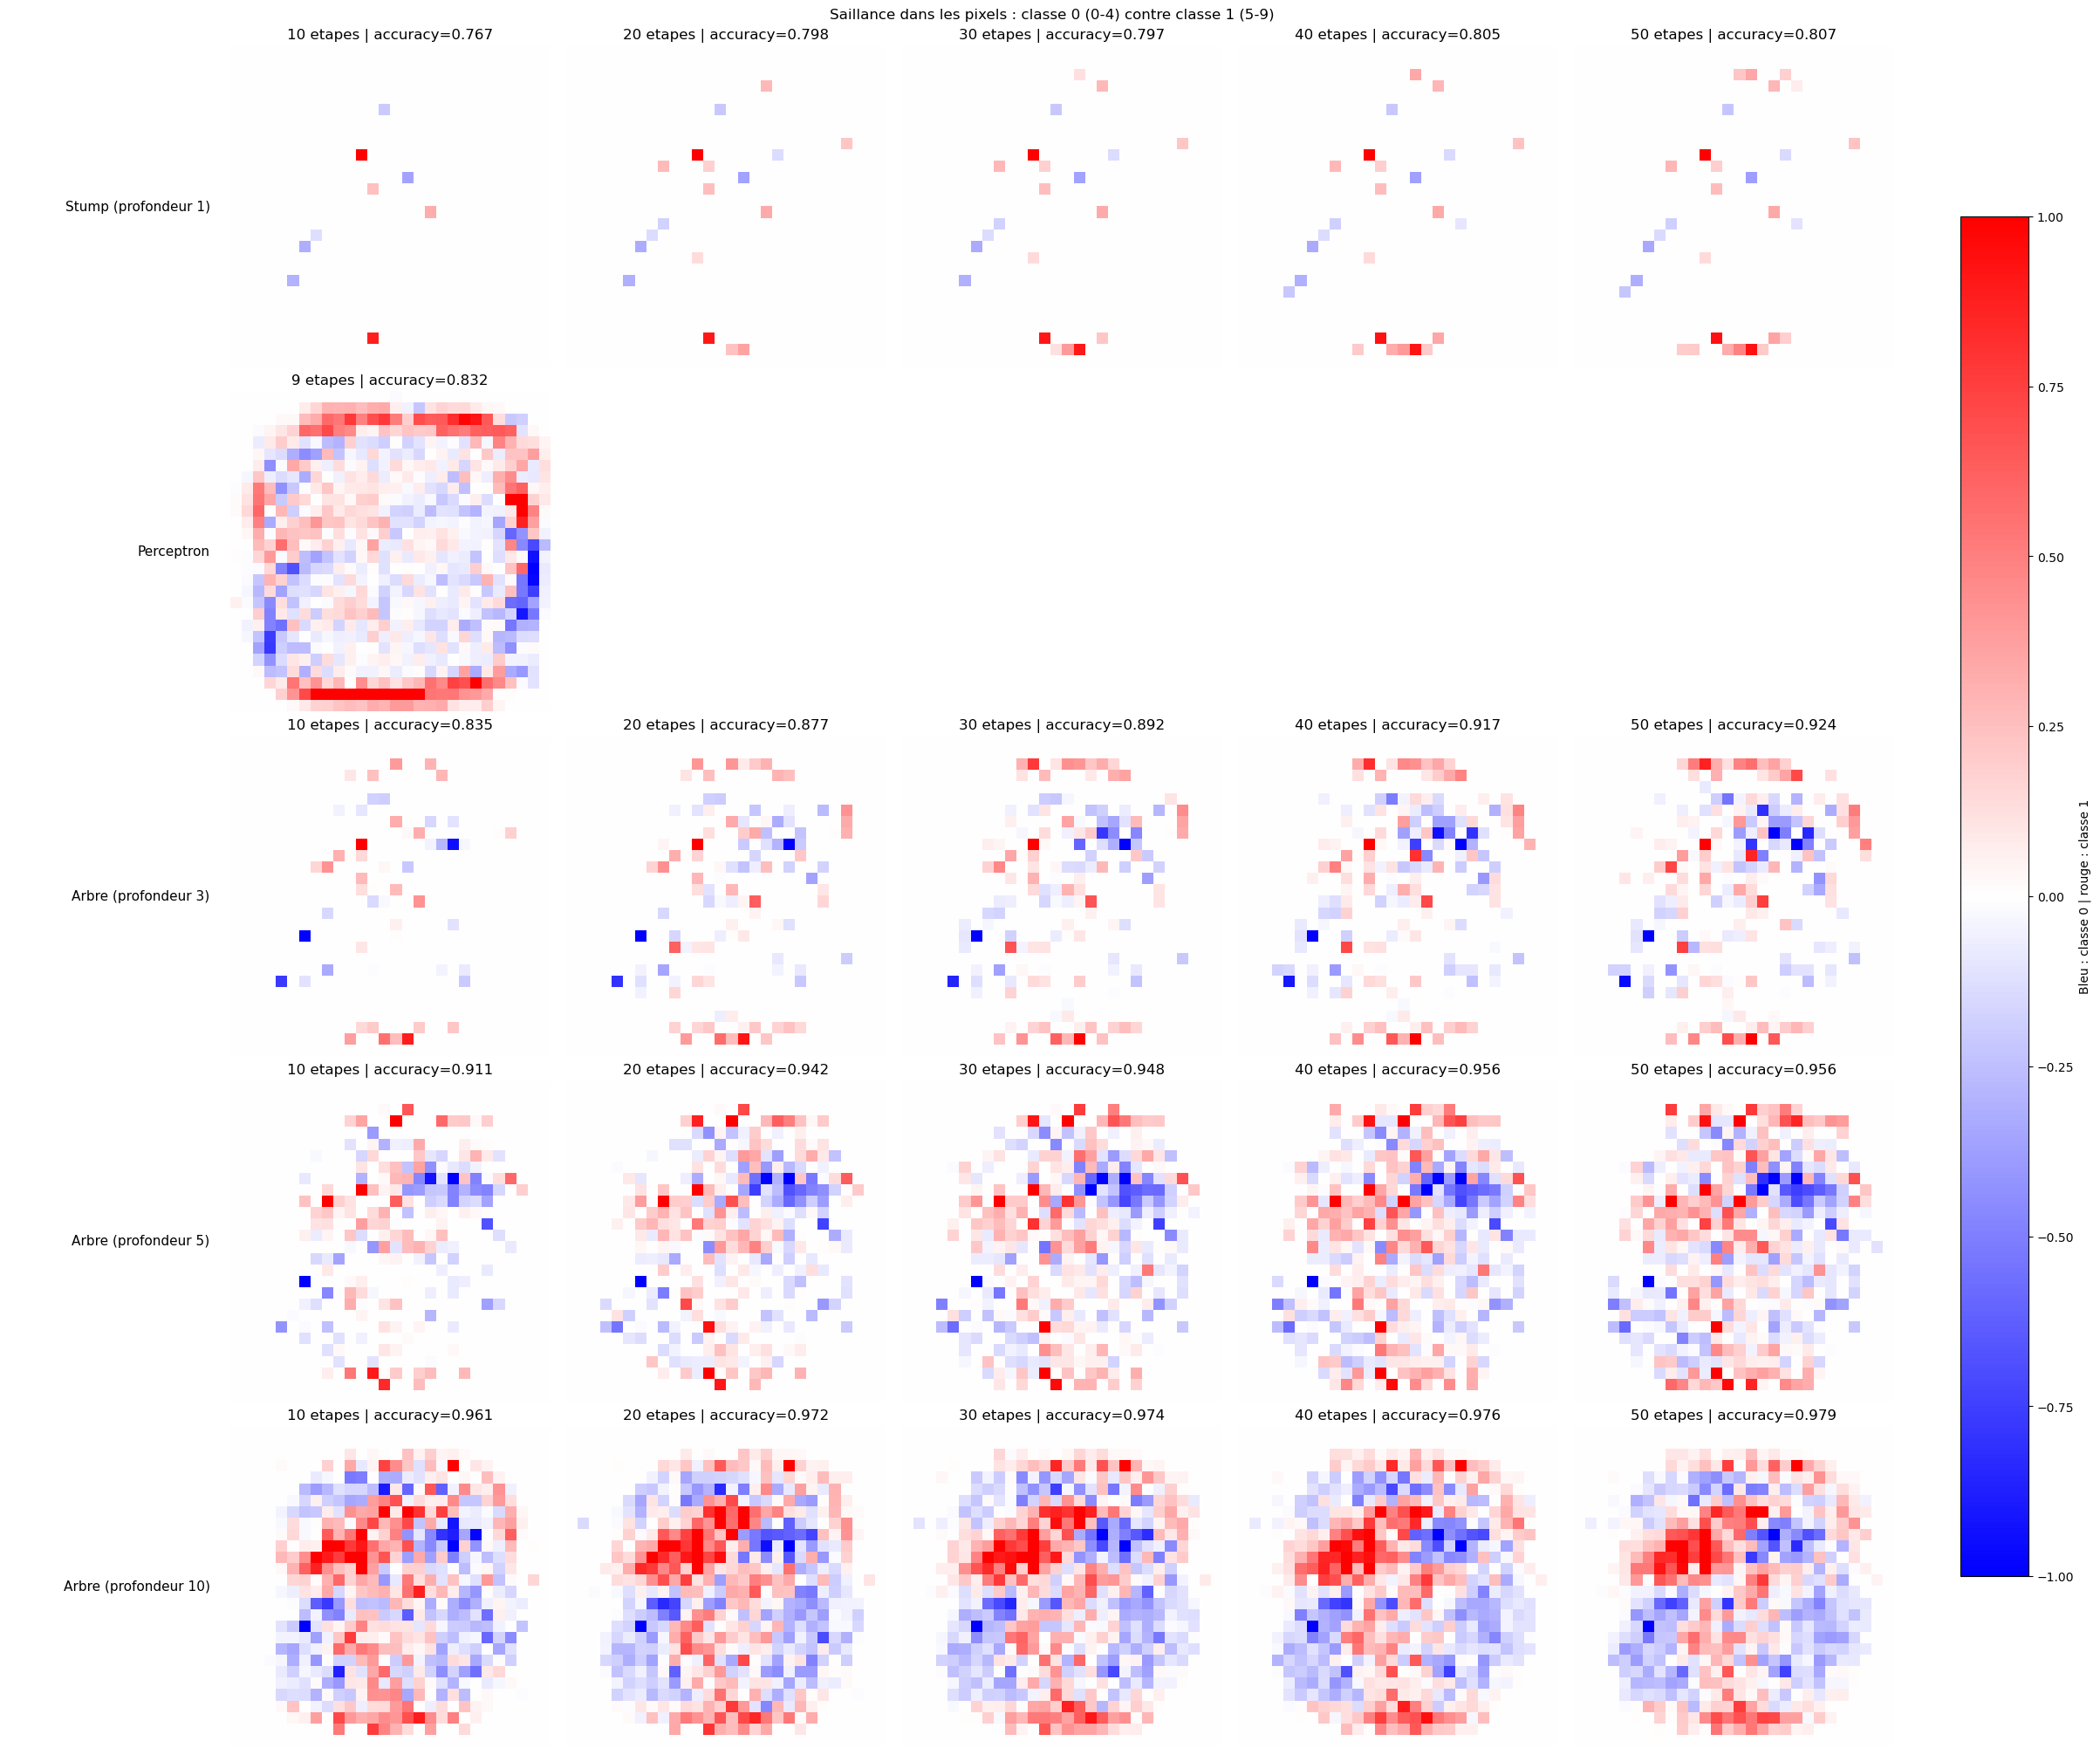

In [38]:
ETAPES_CARTES = [10, 20, 30, 40, 50]

def importance_signee_arbre(classifieur):
    arbre = classifieur.tree_
    importance = np.zeros(arbre.n_features)
    gain_total = 0
    for noeud in range(arbre.node_count):
        gauche = arbre.children_left[noeud]
        if gauche == -1:
            continue
        droite = arbre.children_right[noeud]
        p_gauche = arbre.value[gauche, 0, 1] / arbre.value[gauche, 0].sum()
        p_droite = arbre.value[droite, 0, 1] / arbre.value[droite, 0].sum()
        gain = (
            arbre.weighted_n_node_samples[noeud] * arbre.impurity[noeud]
            - arbre.weighted_n_node_samples[gauche] * arbre.impurity[gauche]
            - arbre.weighted_n_node_samples[droite] * arbre.impurity[droite]
        )
        importance[arbre.feature[noeud]] += gain * (p_droite - p_gauche)
        gain_total += gain
    return importance / gain_total if gain_total else importance

def carte_saillance_pixels(modele, nb_etapes):
    carte = np.zeros(X_train_bin.shape[1])
    for classifieur, poids in zip(
        modele.estimators_[:nb_etapes], modele.estimator_weights_[:nb_etapes]
    ):
        if isinstance(classifieur, Perceptron):
            coefficients = classifieur.coef_[0]
            norme = np.linalg.norm(coefficients)
            if norme > 0:
                carte += poids * coefficients / norme
        else:
            carte += poids * importance_signee_arbre(classifieur)
    return carte.reshape(28, 28)

def afficher_carte(ax, carte):
    valeurs = np.abs(carte[carte != 0])
    limite = np.percentile(valeurs, 98) if valeurs.size else 1
    if limite == 0:
        limite = 1
    image = ax.imshow(
        np.clip(carte / limite, -1, 1), cmap='bwr', vmin=-1, vmax=1
    )
    ax.axis('off')
    return image

fig, axes = plt.subplots(
    len(configurations), len(ETAPES_CARTES) + 1,
    figsize=(24, 4 * len(configurations)), squeeze=False,
    constrained_layout=True,
    gridspec_kw={'width_ratios': [2.5] + [4] * len(ETAPES_CARTES)}
)
cartes_pixels = {}
# Rebuild models if they were not kept in memory
if 'modeles' not in globals():
    modeles = {}
    for nom, classifieur in configurations.items():
        modele = creer_adaboost(classifieur, NB_ETAPES)
        modele.fit(X_train_bin, y_train_bin)
        modeles[nom] = modele

for i, (nom, modele) in enumerate(modeles.items()):
    etapes = sorted({min(n, len(modele.estimators_)) for n in ETAPES_CARTES})
    cartes_pixels[nom] = {}
    axes[i, 0].axis('off')
    axes[i, 0].text(0.98, 0.5, nom, ha='right', va='center', fontsize=11, wrap=True)
    for j, n in enumerate(etapes):
        carte = carte_saillance_pixels(modele, n)
        cartes_pixels[nom][n] = carte
        matrice = matrices[nom][n]
        accuracy = np.trace(matrice) / matrice.sum()
        image = afficher_carte(axes[i, j + 1], carte)
        axes[i, j + 1].set_title(f'{n} etapes | accuracy={accuracy:.3f}')
    for j in range(len(etapes), len(ETAPES_CARTES)):
        axes[i, j + 1].axis('off')

barre = fig.colorbar(image, ax=axes[:, 1:], shrink=0.8, pad=0.04)
barre.set_label('Bleu : classe 0 | rouge : classe 1')
fig.suptitle('Saillance dans les pixels : classe 0 (0-4) contre classe 1 (5-9)')
plt.show()

## 3. AdaBoost dans un embedding

Un MLP apprend a reconstruire les images (784 pixels en entree et en sortie, 64 neurones caches). AdaBoost utilise ensuite les activites de ces 64 neurones pour distinguer les memes groupes que dans la partie 1. Les pixels sont normalises entre 0 et 1 pour entrainer l'autoencodeur.

Dimensions de l embedding : (60000, 64) (10000, 64)
Erreur de reconstruction : 0.00919


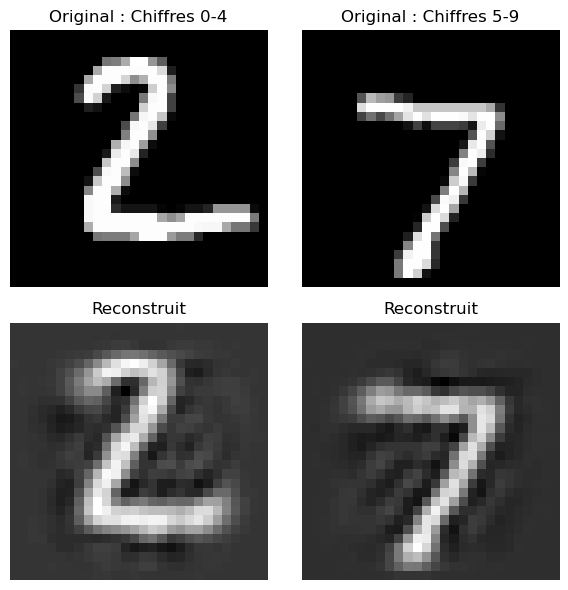

In [39]:
X_train_scaled = X_train.astype(np.float32)
X_train_scaled /= 255.0
X_test_scaled = X_test.astype(np.float32)
X_test_scaled /= 255.0

autoencodeur = MLPRegressor(
    hidden_layer_sizes=(64,), activation='relu',
    max_iter=30, random_state=RANDOM_SEED
)
autoencodeur.fit(X_train_scaled, X_train_scaled)

W_enc = autoencodeur.coefs_[0]
b_enc = autoencodeur.intercepts_[0]

def encoder(X):
    return np.maximum(X @ W_enc + b_enc, 0)

Z_train = encoder(X_train_scaled)
Z_test = encoder(X_test_scaled)
reconstruction = autoencodeur.predict(X_test_scaled)
erreur = np.mean((reconstruction - X_test_scaled) ** 2)
print('Dimensions de l embedding :', Z_train.shape, Z_test.shape)
print('Erreur de reconstruction :', round(float(erreur), 5))

fig, axes = plt.subplots(2, 2, figsize=(6, 6))
for colonne, classe in enumerate([0, 1]):
    indice = np.flatnonzero(y_test_bin == classe)[0]
    axes[0, colonne].imshow(X_test_scaled[indice].reshape(28, 28), cmap='gray')
    axes[1, colonne].imshow(reconstruction[indice].reshape(28, 28), cmap='gray')
    axes[0, colonne].set_title(f'Original : {noms_classes[classe]}')
    axes[1, colonne].set_title('Reconstruit')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

Entrainement dans l embedding : Stump (profondeur 1)
Stump (profondeur 1) - 1 etape(s) :
[[2761 2378]
 [1140 3721]]
Stump (profondeur 1) - 10 etape(s) :
[[3319 1820]
 [1088 3773]]
Stump (profondeur 1) - 20 etape(s) :
[[3622 1517]
 [1112 3749]]
Stump (profondeur 1) - 30 etape(s) :
[[3773 1366]
 [ 981 3880]]
Stump (profondeur 1) - 40 etape(s) :
[[3990 1149]
 [1058 3803]]
Stump (profondeur 1) - 50 etape(s) :
[[4032 1107]
 [1054 3807]]
Entrainement dans l embedding : Perceptron
Perceptron - 1 etape(s) :
[[3295 1844]
 [ 342 4519]]
Perceptron - 10 etape(s) :
[[3800 1339]
 [ 647 4214]]
Perceptron - 15 etape(s) :
[[3769 1370]
 [ 632 4229]]
Entrainement dans l embedding : Arbre (profondeur 3)
Arbre (profondeur 3) - 1 etape(s) :
[[3253 1886]
 [1102 3759]]
Arbre (profondeur 3) - 10 etape(s) :
[[4179  960]
 [ 881 3980]]
Arbre (profondeur 3) - 20 etape(s) :
[[4263  876]
 [ 655 4206]]
Arbre (profondeur 3) - 30 etape(s) :
[[4418  721]
 [ 684 4177]]
Arbre (profondeur 3) - 40 etape(s) :
[[4413  726]
 [

,Classifieur faible,Etapes,Accuracy,Balanced accuracy
0,Arbre (profondeur 10),50,0.9592,0.959163
1,Arbre (profondeur 10),40,0.9562,0.956138
2,Arbre (profondeur 10),30,0.9505,0.950481
3,Arbre (profondeur 10),20,0.9399,0.939968
4,Arbre (profondeur 5),50,0.9264,0.926488
5,Arbre (profondeur 5),40,0.9191,0.919062
6,Arbre (profondeur 10),10,0.9189,0.918896
7,Arbre (profondeur 5),30,0.9109,0.910923
8,Arbre (profondeur 5),20,0.8941,0.894132
9,Arbre (profondeur 3),50,0.8815,0.881467


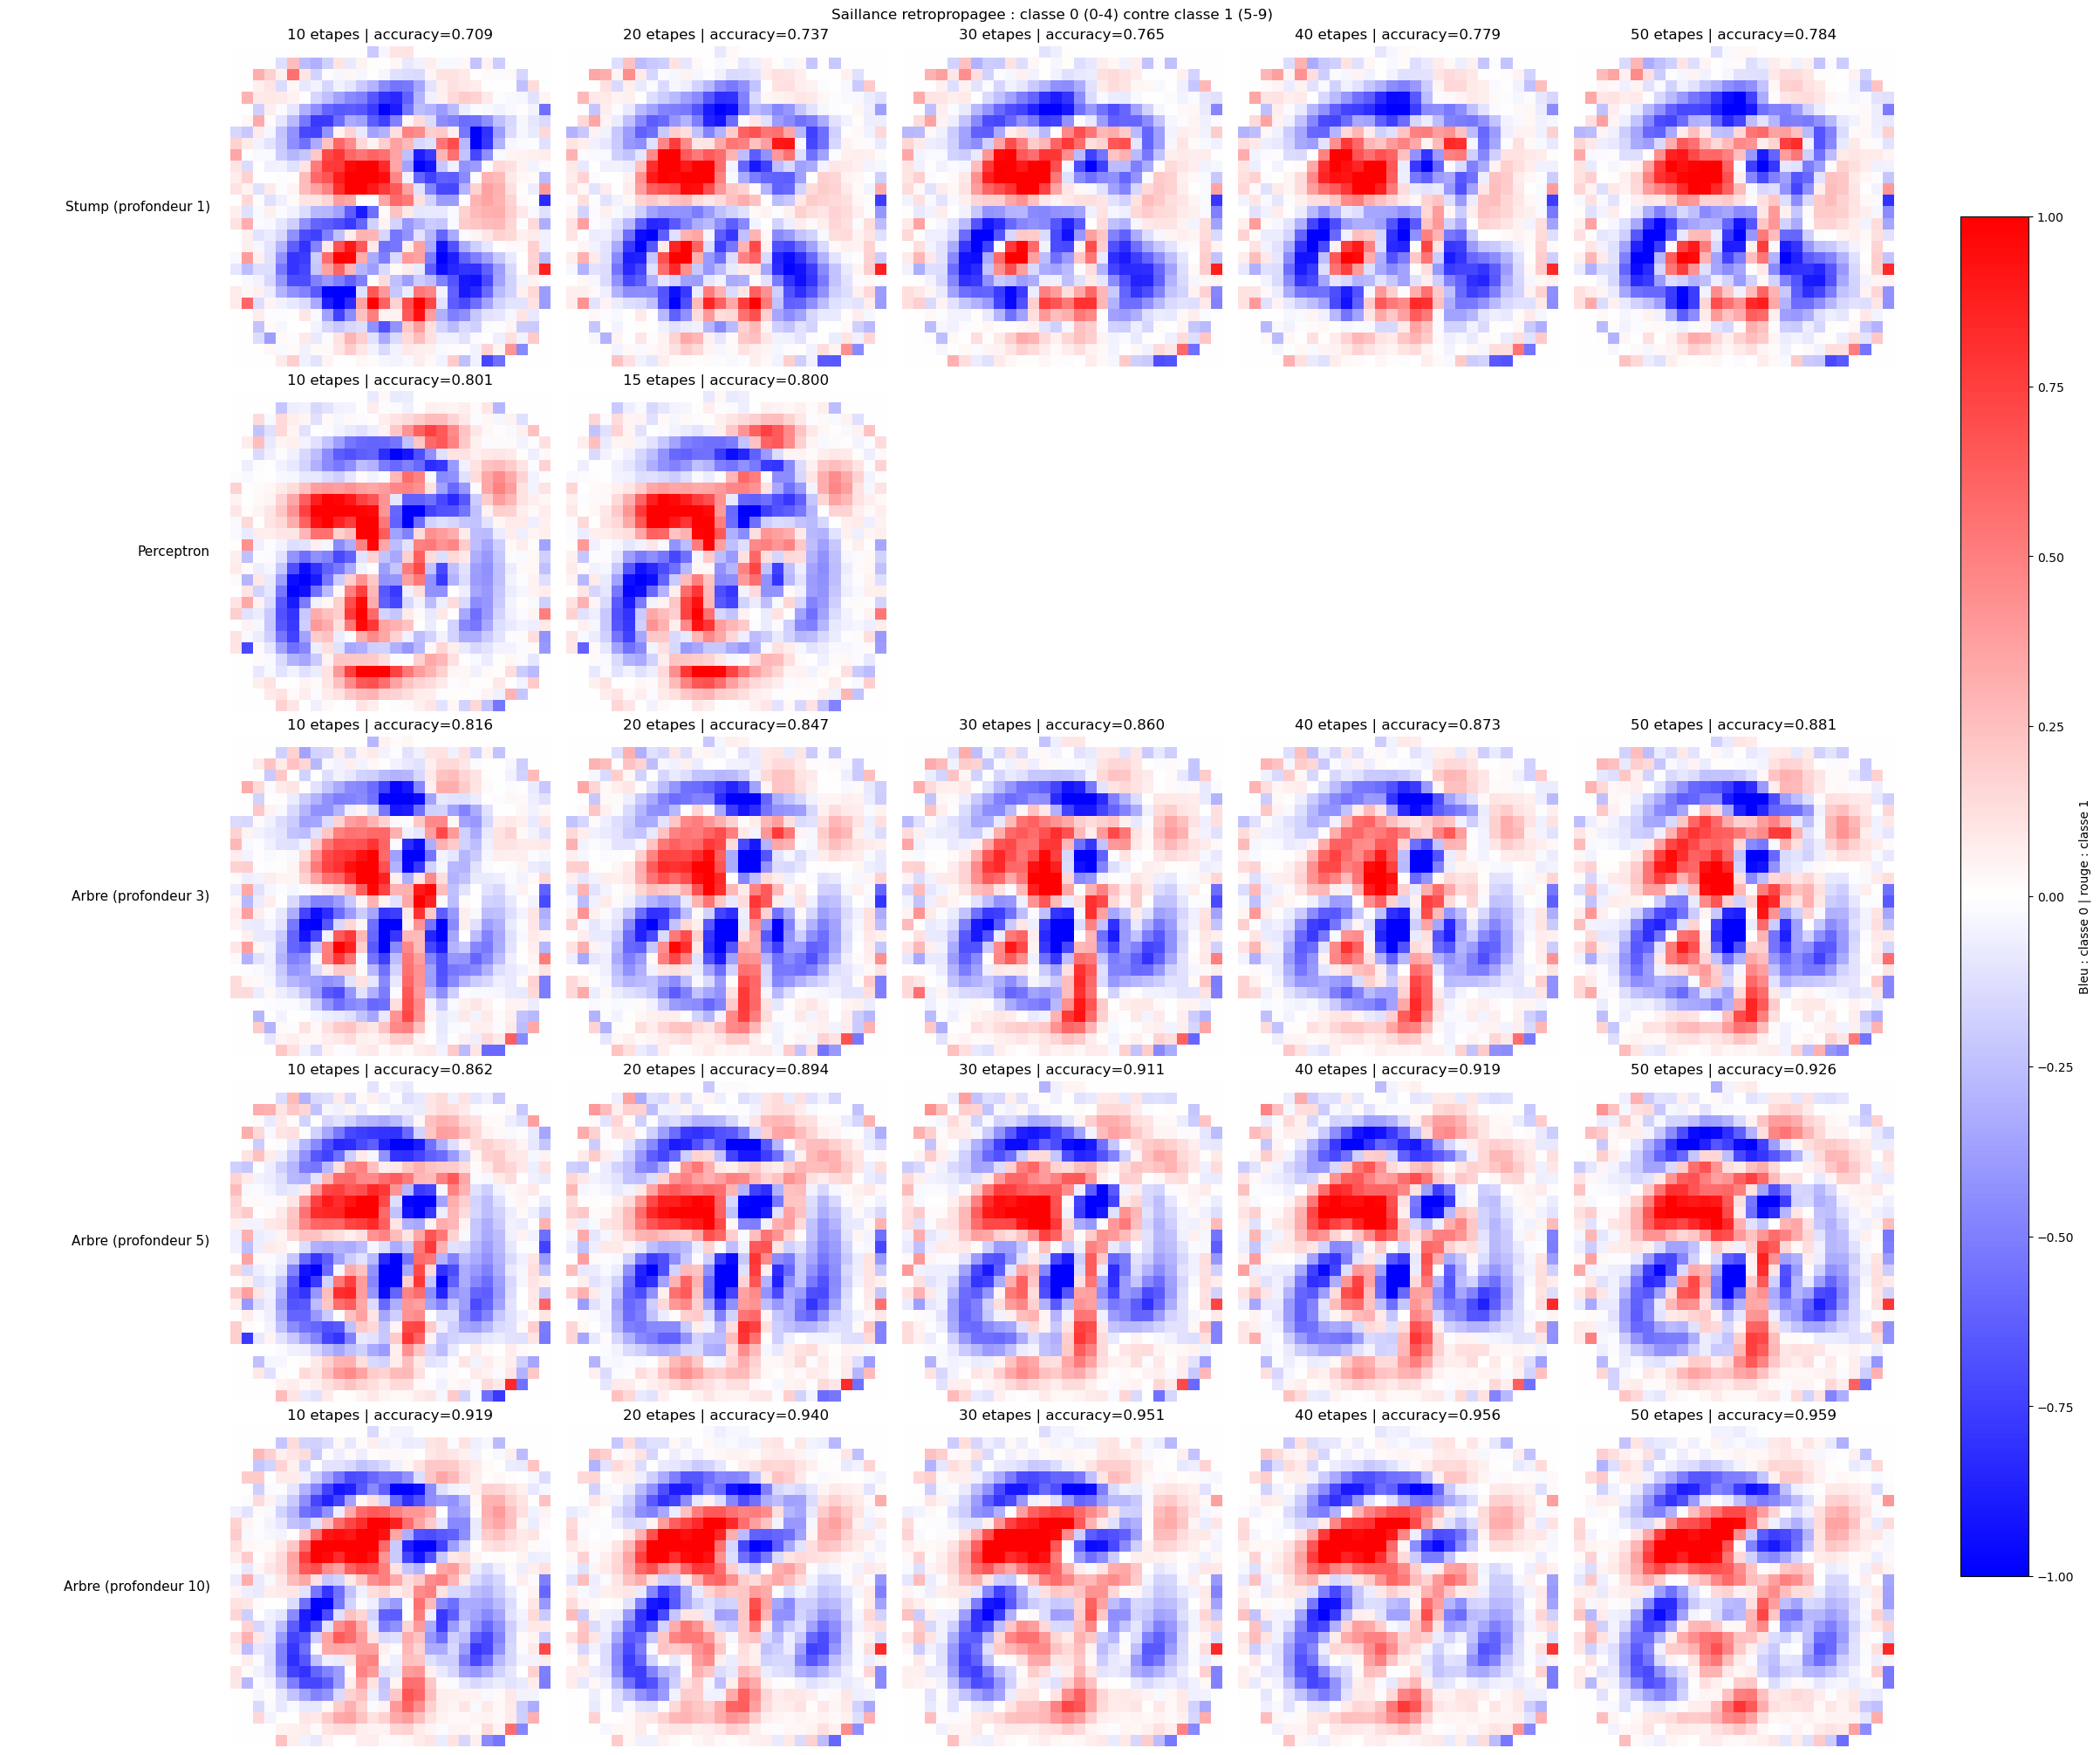

In [40]:
resultats_embedding = []
modeles_embedding = {}
matrices_embedding = {}

for nom, classifieur in configurations.items():
    print('Entrainement dans l embedding :', nom)
    modele = creer_adaboost(classifieur, NB_ETAPES)
    modele.fit(Z_train, y_train_bin)
    modeles_embedding[nom] = modele
    matrices_embedding[nom] = {}

    etapes_effectives = sorted(
        {min(n, len(modele.estimators_)) for n in ETAPES_A_EVALUER}
    )
    for n, prediction in enumerate(modele.staged_predict(Z_test), start=1):
        if n not in etapes_effectives:
            continue
        cm = confusion_matrix(y_test_bin, prediction, labels=[0, 1])
        matrices_embedding[nom][n] = cm
        resultats_embedding.append({
            'Classifieur faible': nom,
            'Etapes': n,
            'Accuracy': accuracy_score(y_test_bin, prediction),
            'Balanced accuracy': balanced_accuracy_score(y_test_bin, prediction),
        })
        print(f'{nom} - {n} etape(s) :\n{cm}')

table_embedding = pd.DataFrame(resultats_embedding)
display(table_embedding.sort_values(
    ['Balanced accuracy', 'Accuracy'], ascending=False
).reset_index(drop=True))

derivee_moyenne = (X_train_scaled @ W_enc + b_enc > 0).mean(axis=0)

def carte_saillance_embedding(modele, nb_etapes):
    coefficients = np.zeros(W_enc.shape[1])
    for classifieur, poids in zip(
        modele.estimators_[:nb_etapes], modele.estimator_weights_[:nb_etapes]
    ):
        if isinstance(classifieur, Perceptron):
            poids_modele = classifieur.coef_[0]
            norme = np.linalg.norm(poids_modele)
            if norme > 0:
                coefficients += poids * poids_modele / norme
        else:
            coefficients += poids * importance_signee_arbre(classifieur)
    return (W_enc @ (coefficients * derivee_moyenne)).reshape(28, 28)

fig, axes = plt.subplots(
    len(configurations), len(ETAPES_CARTES) + 1,
    figsize=(24, 4 * len(configurations)), squeeze=False,
    constrained_layout=True,
    gridspec_kw={'width_ratios': [2.5] + [4] * len(ETAPES_CARTES)}
)
cartes_embedding = {}
for i, (nom, modele) in enumerate(modeles_embedding.items()):
    etapes = sorted({min(n, len(modele.estimators_)) for n in ETAPES_CARTES})
    cartes_embedding[nom] = {}
    axes[i, 0].axis('off')
    axes[i, 0].text(0.98, 0.5, nom, ha='right', va='center', fontsize=11, wrap=True)
    for j, n in enumerate(etapes):
        carte = carte_saillance_embedding(modele, n)
        cartes_embedding[nom][n] = carte
        matrice = matrices_embedding[nom][n]
        accuracy = np.trace(matrice) / matrice.sum()
        image = afficher_carte(axes[i, j + 1], carte)
        axes[i, j + 1].set_title(f'{n} etapes | accuracy={accuracy:.3f}')
    for j in range(len(etapes), len(ETAPES_CARTES)):
        axes[i, j + 1].axis('off')

barre = fig.colorbar(image, ax=axes[:, 1:], shrink=0.8, pad=0.04)
barre.set_label('Bleu : classe 0 | rouge : classe 1')
fig.suptitle('Saillance retropropagee : classe 0 (0-4) contre classe 1 (5-9)')
plt.show()

### Lecture des cartes

Sur toutes les cartes, le bleu indique une contribution vers la classe 0 (chiffres 0 a 4), le rouge vers la classe 1 (chiffres 5 a 9), et le blanc une contribution faible ou nulle. Dans l'embedding, les coefficients des neurones caches sont retropropages vers les pixels avec les poids du MLP et l'activite moyenne de la fonction ReLU. Le contraste est normalise pour chaque carte : il permet de voir les zones importantes, mais pas de comparer leur intensite absolue entre classifieurs. Comme chaque classe regroupe cinq chiffres, les cartes sont moins faciles a interpreter que pour deux chiffres precis.